# Analiza slučajne promjenljive: eksponencijalna raspodjela

Slučajna promjenljiva se generira iz eksponencijalne raspodjele sa $a=0{,}25$.

**Eksponencijalna raspodjela** sa parametrom $a>0$ (sekcija 2.4):
$$p_X(x)=a\,e^{-ax},\quad x\ge0,\qquad P_X(x)=1-e^{-ax},\quad x\ge0$$
Analitički rezultati (sekcija 2.5.4): $E[X]=\frac1a$ (2.45), $E[X^2]=\frac{2}{a^2}$ (2.46), $\sigma_X^2=\frac{1}{a^2}$ (2.47).
Za $a=0{,}25$: $E[X]=4$, $E[X^2]=32$, $\sigma_X^2=16$.

In [1]:
# Priprema okruženja: kloniranje repozitorija sa SSP bibliotekom (prema README uputstvu)
import os, sys, subprocess

REPO_URL = "https://github.com/ierovic1ba/ssp.git"
SSP_PUTANJA = "/content/ssp" if os.path.isdir("/content") else os.path.abspath("ssp")

if not os.path.isdir(os.path.join(SSP_PUTANJA, "ssp")):
    subprocess.run(["git", "clone", REPO_URL, SSP_PUTANJA], check=True)

sys.path.insert(0, SSP_PUTANJA)   # folder u kojem se nalazi paket ssp/

# Uključivanje često korištenih modula
import numpy as np
import matplotlib.pyplot as plt

# Uključivanje modula ssp
import ssp

# Podešavanje prikaza za rad studenata:
ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
ssp.REZOLUCIJA = "LOW"

## 1. Slučajna promjenljiva
Vrijednosti slučajne promjenljive se sintetiziraju generatorom slučajnih brojeva iz odgovarajuće raspodjele
(`numpy.random`). Prvo se generira $N=100$ realizacija i nacrtaju se.

Nekoliko vrijednosti slučajne promjenjive X: 3.48 0.72 2.00 6.17 2.71 

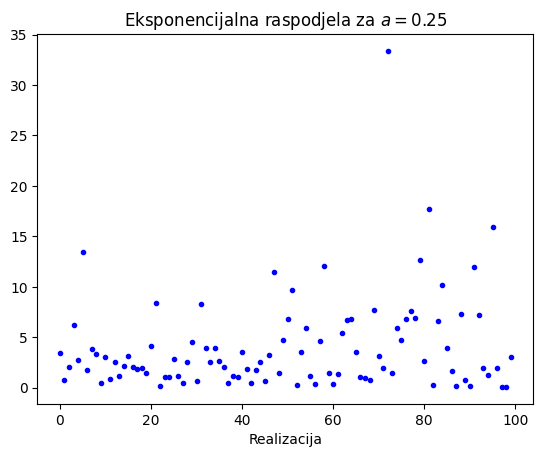

In [2]:
# Generiranje slučajne promjenljive iz eksponencijalne raspodjele

N = 100  # Broj generiranih realizacija
a = 0.25  # Parametar raspodjele (np.random.exponential prima skalu 1/a = 4)

# Vektor od N realizacija slučajne promjenljive:
n = np.arange(N)
X = np.random.exponential(1/a, N)

print("Nekoliko vrijednosti slučajne promjenjive X: ", end="")
for x in X[0:5]:
    print("{:.2f}".format(x), end=" ")

ssp.slprom1D.realizacije(n, X,
                      naslov = "Eksponencijalna raspodjela za $a=0.25$")

U nastavku su nacrtane realizacije slučajne promjenljive zajedno sa očekivanom vrijednošću, odstupanja
promjenljive od očekivane vrijednosti (centrirana promjenljiva), te kvadrati slučajne promjenljive
(izvorne i centrirane).

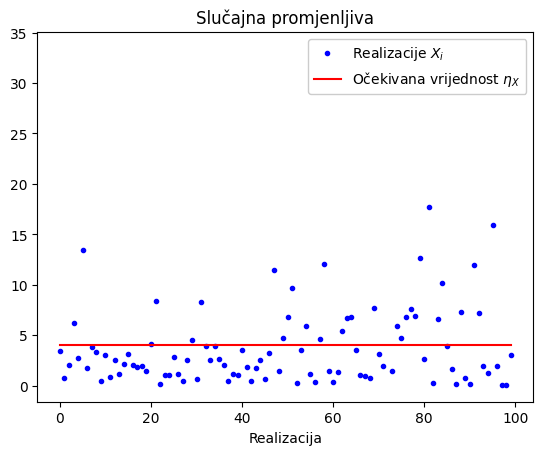

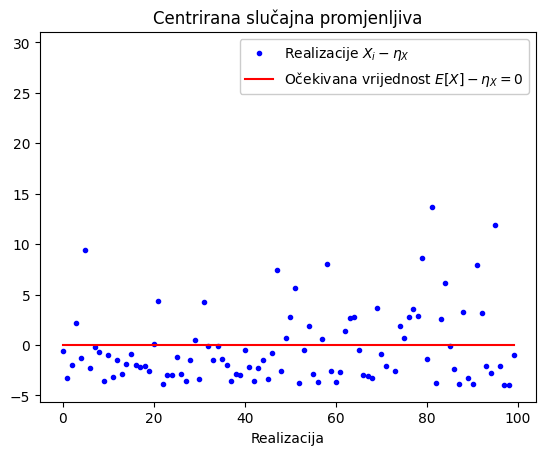

In [3]:
# Očekivana vrijednost slučajne promjenljive:
eta_X = np.mean(X)

#Vektor nad kojim se crta signal
n = np.arange(N)

ssp.slprom1D.realizacije(n, X, n, eta_X,
                      naslov = "Slučajna promjenljiva",
                      legenda = [r'Realizacije $X_i$',
                                 r'Očekivana vrijednost $\eta_X$']);

ssp.slprom1D.realizacije(n, X-eta_X, n, np.mean(X)-eta_X,
                      naslov = "Centrirana slučajna promjenljiva",
                      legenda = [r'Realizacije $X_i-\eta_X$',
                                 r'Očekivana vrijednost $E[X]-\eta_X=0$']);

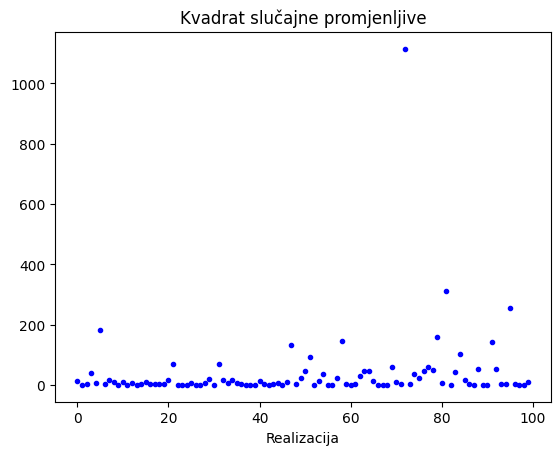

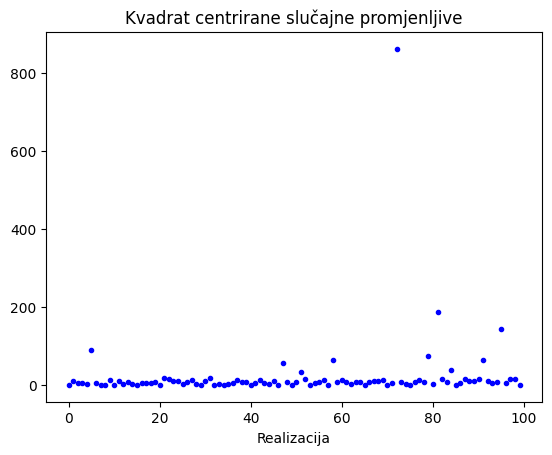

In [4]:
ssp.slprom1D.realizacije(n, X**2,
                        naslov = "Kvadrat slučajne promjenljive")

ssp.slprom1D.realizacije(n, (X - eta_X)**2,
                        naslov = "Kvadrat centrirane slučajne promjenljive")

## 2. Očekivana vrijednost
Za numeričke vrijednosti uzima se više realizacija, $N=2000$. Očekivana vrijednost se može izračunati kao srednja
vrijednost svih realizacija (ručno, petljom, ili gotovom funkcijom `np.mean`), ili analitički relacijom (2.45):
$E[X]=\frac1a$.

In [5]:
a = 0.25; N = 2000; X = np.random.exponential(1/a, N)

suma = 0.0;
for i in range(0, N):
    suma = suma + X[i]

print("Očekivana vrijednost (numerički, 1. način): {:.2f}".format(suma/N))
print("Očekivana vrijednost (numerički, 2. način): {:.2f}".format(np.mean(X)))
print("Očekivana vrijednost (analitički): {:.2f}".format(1/a))

Očekivana vrijednost (numerički, 1. način): 3.94
Očekivana vrijednost (numerički, 2. način): 3.94
Očekivana vrijednost (analitički): 4.00


Prva dva načina se ne razlikuju (to je isti račun), dok se analitički rezultat nešto razlikuje zbog konačnog broja realizacija $N$.

## 3. Srednjekvadratna vrijednost
Srednjekvadratna vrijednost je srednja vrijednost kvadrata realizacija, a analitički se dobiva relacijom (2.46):
$E[X^2]=\frac{2}{a^2}$.

In [6]:
print("Srednjekvadratna vrijednost (numerički): {:.2f}".format(np.mean(X*X)))
print("Srednjekvadratna vrijednost (analitički): {:.2f}".format(2/(a**2)))

Srednjekvadratna vrijednost (numerički): 31.29
Srednjekvadratna vrijednost (analitički): 32.00


## 4. Varijansa
Varijansa se može izračunati gotovom funkcijom `np.var`, po definiciji $E[(X-\eta_X)^2]$, preko veze
$\sigma_X^2=E[X^2]-\eta_X^2$, ili analitički relacijom (2.47): $\sigma_X^2=\frac{1}{a^2}$.

In [7]:
eta_X = np.mean(X)
sigma_X_2 = np.mean(X**2)

print("Varijansa (numerički, 1.način): {:.2f}".format(np.var(X)))
print("Varijansa (numerički, 2.način): {:.2f}".format(np.mean((X - eta_X)**2)))
print("Varijansa (numerički, 3.način): {:.2f}".format(sigma_X_2 - (eta_X**2)))
print("Varijansa (analitički): {:.2f}".format(1/(a**2)))

Varijansa (numerički, 1.način): 15.73
Varijansa (numerički, 2.način): 15.73
Varijansa (numerički, 3.način): 15.73
Varijansa (analitički): 16.00


## 5. Medijana
Medijana $m$ je vrijednost za koju je vjerovatnoća($X\le m$) = vjerovatnoća($X\ge m$) $=\tfrac12$ (2.48),
tj. $P_X(m)=\tfrac12$. Numerički se računa gotovom funkcijom `np.median`. Analitički, iz $P_X(m)=\tfrac12$
slijedi $1-e^{-am}=\frac12\ \Rightarrow\ m=\frac{\ln2}{a}$.

In [8]:
print("Medijana: {:.2f}".format(np.median(X)))
print("Medijana (analitički): {:.2f}".format(np.log(2)/a))

Medijana: 2.62
Medijana (analitički): 2.77


## 6. Funkcija raspodjele i funkcija gustine vjerovatnoće
Funkcija raspodjele vjerovatnoće se procjenjuje po definiciji: $P_X(x)$ je udio realizacija koje su $\le x$
(`ssp.slprom1D.PDF`). Funkcija gustine je njen izvod, $p_X(x)=\dfrac{dP_X(x)}{dx}$, koji se numerički
računa kao razlika susjednih vrijednosti podijeljena korakom (`ssp.slprom1D.pdf`).
Na kraju se eksperimentalne funkcije porede sa teoretskim:

$$P_X(x)=1-e^{-ax}\ \ (x\ge0),\qquad p_X(x)=a\,e^{-ax}\ \ (x\ge0)$$

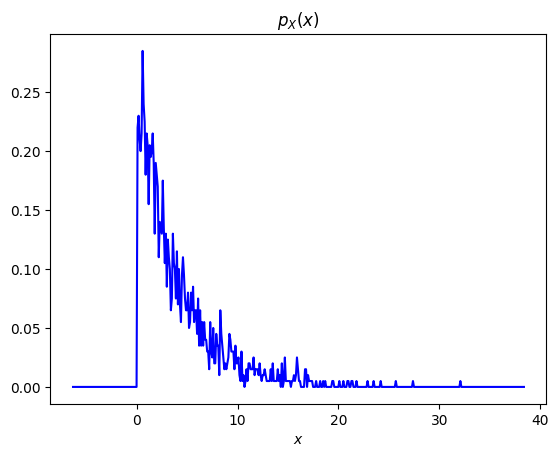

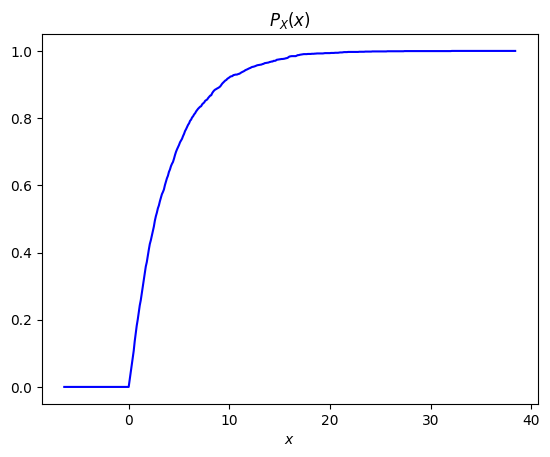

In [9]:
x, px = ssp.slprom1D.pdf(X)

x, Px = ssp.slprom1D.PDF(X)

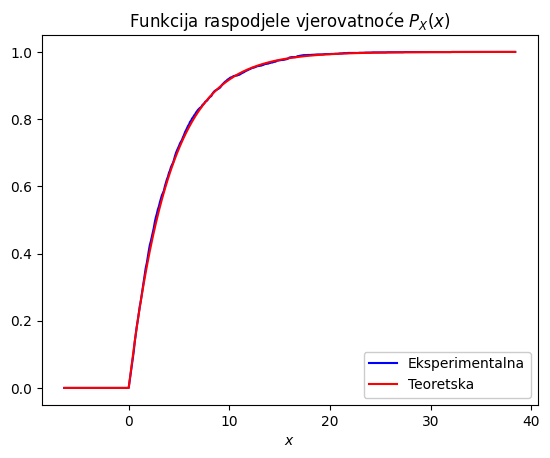

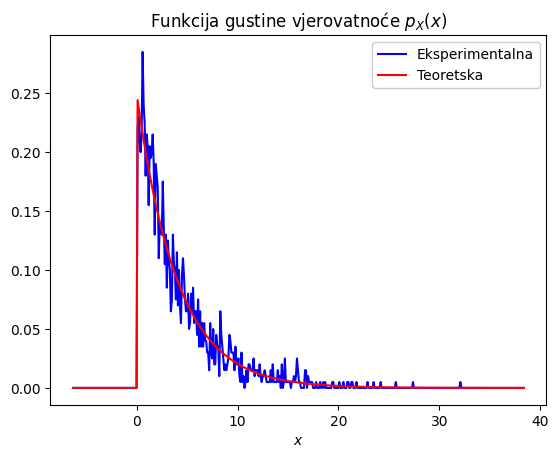

In [10]:
# Teoretske funkcije eksponencijalne raspodjele
def P_teor(x):
    return np.where(x >= 0, 1 - np.exp(-a*x), 0)

def p_teor(x):
    return np.where(x >= 0, a*np.exp(-a*x), 0)

x, Px = ssp.slprom1D.PDF(X, prikaz = False)
ssp.slprom1D.grafik(x, Px, x, P_teor(x),
                 naslov = "Funkcija raspodjele vjerovatnoće $P_X(x)$",
                 legenda = ['Eksperimentalna', 'Teoretska'],
                 lokacija_lgd = 'lower right',
                 x_labela = "$x$")

x, px = ssp.slprom1D.pdf(X, prikaz = False)
ssp.slprom1D.grafik(x, px, x, p_teor(x),
                 naslov = "Funkcija gustine vjerovatnoće $p_X(x)$",
                 legenda = ['Eksperimentalna', 'Teoretska'],
                 x_labela = "$x$")

## 7. Sažetak

In [11]:
print("{:<28s}{:>12s}{:>12s}".format("", "numerički", "analitički"))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Očekivana vrijednost", np.mean(X), 1/a))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Srednjekvadratna vrijednost", np.mean(X**2), 2/(a**2)))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Varijansa", np.var(X), 1/(a**2)))
print("{:<28s}{:>12.4f}{:>12.4f}".format("Medijana", np.median(X), np.log(2)/a))

                               numerički  analitički
Očekivana vrijednost              3.9448      4.0000
Srednjekvadratna vrijednost      31.2912     32.0000
Varijansa                        15.7298     16.0000
Medijana                          2.6188      2.7726


**Zaključak.** Eksponencijalna promjenljiva je uvijek pozitivna, najgušće su male vrijednosti, a gustina opada od
$p_X(0)=a$ prema nuli. Rep je još „teži“ nego kod Rayleigheve raspodjele, pa je razlika između očekivane vrijednosti
($1/a=4$) i medijane ($\ln2/a\approx2{,}77$) velika. Standardna devijacija je jednaka očekivanoj vrijednosti ($\sigma_X=1/a$).